In [64]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

print("successfully  imported ")

successfully  imported 


In [65]:
df = pd.read_csv("Crop_recommendation.csv")
print("successfully dataset loaded ")

successfully dataset loaded 


In [66]:
print(df.shape)

(2200, 8)


In [67]:
df.head()

,N,P,K,temperature,humidity,ph,rainfall,label
0,90,42,43,20.879744,82.002744,6.502985,202.935536,rice
1,85,58,41,21.770462,80.319644,7.038096,226.655537,rice
2,60,55,44,23.004459,82.320763,7.840207,263.964248,rice
3,74,35,40,26.491096,80.158363,6.980401,242.864034,rice
4,78,42,42,20.130175,81.604873,7.628473,262.717340,rice


In [68]:
df.sample()

,N,P,K,temperature,humidity,ph,rainfall,label
370,37,56,25,22.055923,19.603793,5.774755,126.726537,kidneybeans


In [69]:
print("Column names:")
print(df.columns.tolist())

Column names:
['N', 'P', 'K', 'temperature', 'humidity', 'ph', 'rainfall', 'label']


In [70]:
print("Dataset information:")
df.info()

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2200 entries, 0 to 2199
Data columns (total 8 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   N            2200 non-null   int64  
 1   P            2200 non-null   int64  
 2   K            2200 non-null   int64  
 3   temperature  2200 non-null   float64
 4   humidity     2200 non-null   float64
 5   ph           2200 non-null   float64
 6   rainfall     2200 non-null   float64
 7   label        2200 non-null   object 
dtypes: float64(4), int64(3), object(1)
memory usage: 137.6+ KB


In [71]:
print("Statistical summary:")
df.describe()

Statistical summary:


,N,P,K,temperature,humidity,ph,rainfall
count,2200.000000,2200.000000,2200.000000,2200.000000,2200.000000,2200.000000,2200.000000
mean,50.551818,53.362727,48.149091,25.616244,71.481779,6.469480,103.463655
std,36.917334,32.985883,50.647931,5.063749,22.263812,0.773938,54.958389
min,0.000000,5.000000,5.000000,8.825675,14.258040,3.504752,20.211267
25%,21.000000,28.000000,20.000000,22.769375,60.261953,5.971693,64.551686
50%,37.000000,51.000000,32.000000,25.598693,80.473146,6.425045,94.867624
75%,84.250000,68.000000,49.000000,28.561654,89.948771,6.923643,124.267508
max,140.000000,145.000000,205.000000,43.675493,99.981876,9.935091,298.560117


In [72]:
print("Missing values in each column:")
print(df.isnull().sum())

Missing values in each column:
N              0
P              0
K              0
temperature    0
humidity       0
ph             0
rainfall       0
label          0
dtype: int64


In [73]:
print("Total missing values:")
print(df.isnull().sum().sum())

Total missing values:
0


In [74]:
print("Number of duplicate rows:")
print(df.duplicated().sum())

Number of duplicate rows:
0


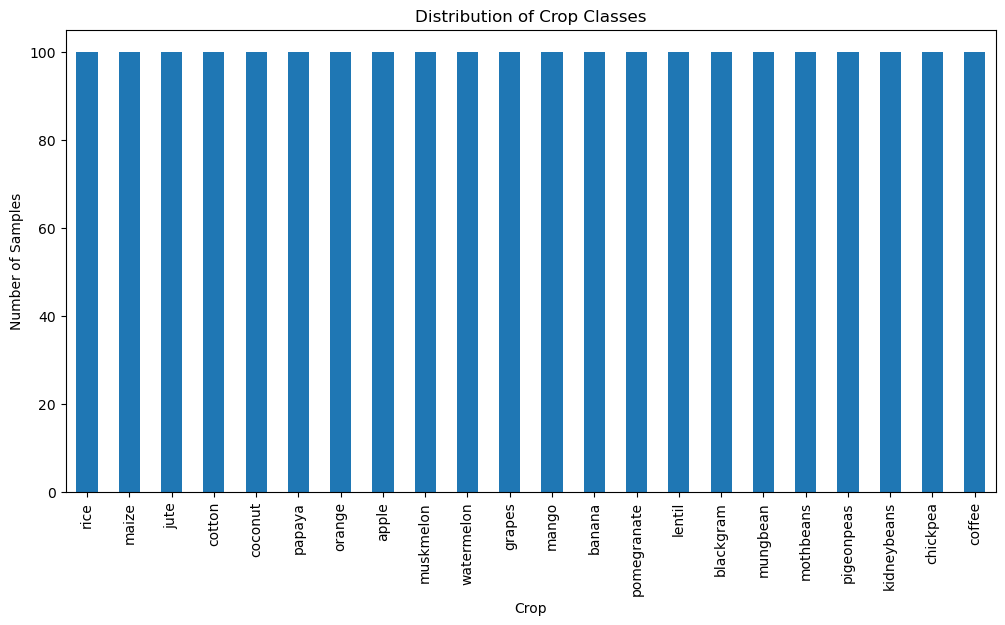

In [75]:
crop_counts = df["label"].value_counts()
plt.figure(figsize=(12, 6))
crop_counts.plot(kind="bar")

plt.title("Distribution of Crop Classes")
plt.xlabel("Crop")
plt.ylabel("Number of Samples")
plt.show()

In [76]:
X = df.drop("label", axis=1)
y = df["label"]

In [77]:
X

,N,P,K,temperature,humidity,ph,rainfall
0,90,42,43,20.879744,82.002744,6.502985,202.935536
1,85,58,41,21.770462,80.319644,7.038096,226.655537
2,60,55,44,23.004459,82.320763,7.840207,263.964248
3,74,35,40,26.491096,80.158363,6.980401,242.864034
4,78,42,42,20.130175,81.604873,7.628473,262.717340
...,...,...,...,...,...,...,...
2195,107,34,32,26.774637,66.413269,6.780064,177.774507
2196,99,15,27,27.417112,56.636362,6.086922,127.924610
2197,118,33,30,24.131797,67.225123,6.362608,173.322839
2198,117,32,34,26.272418,52.127394,6.758793,127.175293


In [78]:
y

0         rice
1         rice
2         rice
3         rice
4         rice
         ...  
2195    coffee
2196    coffee
2197    coffee
2198    coffee
2199    coffee
Name: label, Length: 2200, dtype: object

In [79]:
print(X.columns.tolist())

['N', 'P', 'K', 'temperature', 'humidity', 'ph', 'rainfall']


In [80]:
print(y.head())

0    rice
1    rice
2    rice
3    rice
4    rice
Name: label, dtype: object


In [81]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size = 0.2,
    random_state = 42,
    # stratify = y
)

In [82]:
x1 = X_train.shape
print(x1)

(1760, 7)


In [83]:
x2 = X_test.shape
print(x2)

(440, 7)


In [84]:
print(y_train.shape)

(1760,)


In [85]:
print(y_test.shape)

(440,)


In [86]:
linear_svm = make_pipeline(
    StandardScaler(),
    SVC(kernel= "linear")
)
print("Linear SVM model created")

Linear SVM model created


In [87]:
polynomial_svm = make_pipeline(
    StandardScaler(),
    SVC(kernel="poly", degree=3)
)
print("Polynomial SVM model created:)")

Polynomial SVM model created:)


In [88]:
rbf_svm = make_pipeline(
    StandardScaler(),
    SVC(kernel="rbf")
)
print("RBF SVM model created")

RBF SVM model created


In [89]:
decision_tree = DecisionTreeClassifier(random_state=42)
print("Decision Tree model created")

Decision Tree model created


In [90]:
models = {
    "SVM Linear": linear_svm,
    "SVM Polynomial": polynomial_svm,
    "SVM RBF": rbf_svm,
    "Decision Tree": decision_tree
}
print("All models are ready")

All models are ready


In [91]:
for name in models:
    print(name)

SVM Linear
SVM Polynomial
SVM RBF
Decision Tree


In [92]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)
print("5-fold cross-validation is ready")

5-fold cross-validation is ready


In [93]:
results = []

for name, model in models.items():

    scores = cross_validate(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring={
            "accuracy": "accuracy",
            "precision": "precision_macro",
            "recall": "recall_macro",
            "f1": "f1_macro"
        }
    ) 
    results.append({
        "Model": name,
        "Accuracy": scores["test_accuracy"].mean(),
        "Precision": scores["test_precision"].mean(),
        "Recall": scores["test_recall"].mean(),
        "F1-score": scores["test_f1"].mean()
    })

results_df = pd.DataFrame(results)

print(results_df.round(4))  

            Model  Accuracy  Precision  Recall  F1-score
0      SVM Linear    0.9818     0.9836  0.9820    0.9819
1  SVM Polynomial    0.9318     0.9528  0.9312    0.9347
2         SVM RBF    0.9847     0.9868  0.9848    0.9845
3   Decision Tree    0.9847     0.9858  0.9843    0.9844


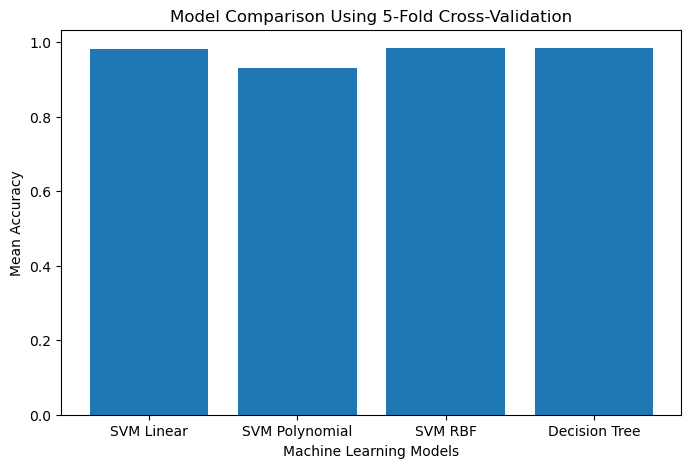

In [94]:
plt.figure(figsize=(8, 5))

plt.bar(results_df["Model"], results_df["Accuracy"])

plt.title("Model Comparison Using 5-Fold Cross-Validation")
plt.xlabel("Machine Learning Models")
plt.ylabel("Mean Accuracy")

plt.show()

In [95]:
for name, model in models.items():
    model.fit(X_train, y_train)

print("All models trained successfully")

All models trained successfully


In [96]:
test_results = []

for name, model in models.items():

    y_pred = model.predict(X_test)

    test_results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, average="macro"),
        "Recall": recall_score(y_test, y_pred, average="macro"),
        "F1-score": f1_score(y_test, y_pred, average="macro")
    })

test_results_df = pd.DataFrame(test_results)

print(test_results_df.round(4))

            Model  Accuracy  Precision  Recall  F1-score
0      SVM Linear    0.9773     0.9776  0.9785    0.9771
1  SVM Polynomial    0.9205     0.9371  0.9233    0.9224
2         SVM RBF    0.9682     0.9677  0.9695    0.9666
3   Decision Tree    0.9864     0.9861  0.9873    0.9864


In [97]:
# Store predictions from all four models

predictions = pd.DataFrame(index=y_test.index)

for name, model in models.items():
    predictions[name] = model.predict(X_test)

# Add the actual crop labels
predictions["Actual"] = y_test.to_numpy()

# Display the first 10 predictions
predictions.head(10)


,SVM Linear,SVM Polynomial,SVM RBF,Decision Tree,Actual
1451,muskmelon,muskmelon,muskmelon,muskmelon,muskmelon
1334,watermelon,watermelon,watermelon,watermelon,watermelon
1761,papaya,papaya,papaya,papaya,papaya
1735,papaya,papaya,papaya,papaya,papaya
1576,apple,apple,apple,apple,apple
1110,mango,mango,mango,mango,mango
1594,apple,apple,apple,apple,apple
530,mothbeans,maize,mothbeans,mothbeans,mothbeans
651,mungbean,mungbean,mungbean,mungbean,mungbean
819,lentil,lentil,lentil,lentil,lentil


In [98]:
model_columns = list(models.keys())

for name in model_columns:
    wrong = predictions[predictions[name] != predictions["Actual"]]

    print(f"\n{name}")
    print("Total wrong predictions:", len(wrong))
    print("Error rate:", round(len(wrong) / len(predictions) * 100, 2), "%")



SVM Linear
Total wrong predictions: 10
Error rate: 2.27 %

SVM Polynomial
Total wrong predictions: 35
Error rate: 7.95 %

SVM RBF
Total wrong predictions: 14
Error rate: 3.18 %

Decision Tree
Total wrong predictions: 6
Error rate: 1.36 %


In [99]:
wrong_predictions = predictions[
    predictions[model_columns].ne(predictions["Actual"], axis=0).any(axis=1)
]

print("Total samples with at least one wrong prediction:",
      len(wrong_predictions))

wrong_predictions


Total samples with at least one wrong prediction: 41


,SVM Linear,SVM Polynomial,SVM RBF,Decision Tree,Actual
530,mothbeans,maize,mothbeans,mothbeans,mothbeans
508,mothbeans,lentil,lentil,mothbeans,mothbeans
414,pigeonpeas,maize,pigeonpeas,pigeonpeas,pigeonpeas
2110,coffee,maize,coffee,coffee,coffee
746,blackgram,lentil,lentil,blackgram,blackgram
1788,papaya,mungbean,papaya,papaya,papaya
408,blackgram,maize,pigeonpeas,pigeonpeas,pigeonpeas
1626,orange,pomegranate,orange,orange,orange
2133,coffee,maize,coffee,coffee,coffee
73,jute,jute,jute,rice,rice


In [100]:
for name in model_columns:
    wrong = predictions[predictions[name] != predictions["Actual"]]

    print("\nWrong predictions by:", name)
    display(wrong[[name, "Actual"]])



Wrong predictions by: SVM Linear


,SVM Linear,Actual
408,blackgram,pigeonpeas
73,jute,rice
70,jute,rice
135,cotton,maize
571,lentil,mothbeans
65,jute,rice
13,jute,rice
438,kidneybeans,pigeonpeas
2012,rice,jute
482,kidneybeans,pigeonpeas



Wrong predictions by: SVM Polynomial


,SVM Polynomial,Actual
530,maize,mothbeans
508,lentil,mothbeans
414,maize,pigeonpeas
2110,maize,coffee
746,lentil,blackgram
1788,mungbean,papaya
408,maize,pigeonpeas
1626,pomegranate,orange
2133,maize,coffee
73,jute,rice



Wrong predictions by: SVM RBF


,SVM RBF,Actual
508,lentil,mothbeans
746,lentil,blackgram
73,jute,rice
70,jute,rice
135,cotton,maize
56,jute,rice
571,lentil,mothbeans
65,jute,rice
2005,coffee,jute
13,jute,rice



Wrong predictions by: Decision Tree


,Decision Tree,Actual
135,coconut,maize
538,blackgram,mothbeans
65,jute,rice
13,jute,rice
2012,rice,jute
588,lentil,mothbeans


In [101]:
model_columns = list(models.keys())

# Check whether all models give the same prediction
predictions["Agreement"] = (
    predictions[model_columns].nunique(axis=1) == 1
)

# Count how many models predicted incorrectly
predictions["Correct_Count"] = (
    predictions[model_columns]
    .eq(predictions["Actual"], axis=0)
    .sum(axis=1)
)

predictions["Model_Errors"] = (
    len(model_columns) - predictions["Correct_Count"]
)

print("Total samples:", len(predictions))
print("Agreement cases:", predictions["Agreement"].sum())
print("Disagreement cases:", (~predictions["Agreement"]).sum())

predictions.head(10)


Total samples: 440
Agreement cases: 401
Disagreement cases: 39


,SVM Linear,SVM Polynomial,SVM RBF,Decision Tree,Actual,Agreement,Correct_Count,Model_Errors
1451,muskmelon,muskmelon,muskmelon,muskmelon,muskmelon,True,4,0
1334,watermelon,watermelon,watermelon,watermelon,watermelon,True,4,0
1761,papaya,papaya,papaya,papaya,papaya,True,4,0
1735,papaya,papaya,papaya,papaya,papaya,True,4,0
1576,apple,apple,apple,apple,apple,True,4,0
1110,mango,mango,mango,mango,mango,True,4,0
1594,apple,apple,apple,apple,apple,True,4,0
530,mothbeans,maize,mothbeans,mothbeans,mothbeans,False,3,1
651,mungbean,mungbean,mungbean,mungbean,mungbean,True,4,0
819,lentil,lentil,lentil,lentil,lentil,True,4,0


In [102]:
predictions

,SVM Linear,SVM Polynomial,SVM RBF,Decision Tree,Actual,Agreement,Correct_Count,Model_Errors
1451,muskmelon,muskmelon,muskmelon,muskmelon,muskmelon,True,4,0
1334,watermelon,watermelon,watermelon,watermelon,watermelon,True,4,0
1761,papaya,papaya,papaya,papaya,papaya,True,4,0
1735,papaya,papaya,papaya,papaya,papaya,True,4,0
1576,apple,apple,apple,apple,apple,True,4,0
...,...,...,...,...,...,...,...,...
59,rice,rice,rice,rice,rice,True,4,0
71,rice,rice,rice,rice,rice,True,4,0
1908,cotton,cotton,cotton,cotton,cotton,True,4,0
1958,cotton,cotton,cotton,cotton,cotton,True,4,0


In [103]:
disagreement_cases = predictions[
    predictions["Agreement"] == False
]

disagreement_cases

,SVM Linear,SVM Polynomial,SVM RBF,Decision Tree,Actual,Agreement,Correct_Count,Model_Errors
530,mothbeans,maize,mothbeans,mothbeans,mothbeans,False,3,1
508,mothbeans,lentil,lentil,mothbeans,mothbeans,False,2,2
414,pigeonpeas,maize,pigeonpeas,pigeonpeas,pigeonpeas,False,3,1
2110,coffee,maize,coffee,coffee,coffee,False,3,1
746,blackgram,lentil,lentil,blackgram,blackgram,False,2,2
1788,papaya,mungbean,papaya,papaya,papaya,False,3,1
408,blackgram,maize,pigeonpeas,pigeonpeas,pigeonpeas,False,2,2
1626,orange,pomegranate,orange,orange,orange,False,3,1
2133,coffee,maize,coffee,coffee,coffee,False,3,1
73,jute,jute,jute,rice,rice,False,1,3


In [104]:
wrong_cases = predictions[
    predictions[model_columns].ne(
        predictions["Actual"], axis=0
    ).any(axis=1)
]

wrong_cases

,SVM Linear,SVM Polynomial,SVM RBF,Decision Tree,Actual,Agreement,Correct_Count,Model_Errors
530,mothbeans,maize,mothbeans,mothbeans,mothbeans,False,3,1
508,mothbeans,lentil,lentil,mothbeans,mothbeans,False,2,2
414,pigeonpeas,maize,pigeonpeas,pigeonpeas,pigeonpeas,False,3,1
2110,coffee,maize,coffee,coffee,coffee,False,3,1
746,blackgram,lentil,lentil,blackgram,blackgram,False,2,2
1788,papaya,mungbean,papaya,papaya,papaya,False,3,1
408,blackgram,maize,pigeonpeas,pigeonpeas,pigeonpeas,False,2,2
1626,orange,pomegranate,orange,orange,orange,False,3,1
2133,coffee,maize,coffee,coffee,coffee,False,3,1
73,jute,jute,jute,rice,rice,False,1,3


In [105]:
all_correct_cases = predictions[
    predictions["Correct_Count"] == len(model_columns)
]

all_correct_cases

,SVM Linear,SVM Polynomial,SVM RBF,Decision Tree,Actual,Agreement,Correct_Count,Model_Errors
1451,muskmelon,muskmelon,muskmelon,muskmelon,muskmelon,True,4,0
1334,watermelon,watermelon,watermelon,watermelon,watermelon,True,4,0
1761,papaya,papaya,papaya,papaya,papaya,True,4,0
1735,papaya,papaya,papaya,papaya,papaya,True,4,0
1576,apple,apple,apple,apple,apple,True,4,0
...,...,...,...,...,...,...,...,...
787,blackgram,blackgram,blackgram,blackgram,blackgram,True,4,0
59,rice,rice,rice,rice,rice,True,4,0
71,rice,rice,rice,rice,rice,True,4,0
1908,cotton,cotton,cotton,cotton,cotton,True,4,0


In [106]:
# Check whether at least one model made a wrong prediction
predictions["Any_Model_Wrong"] = (
    predictions["Model_Errors"] > 0
)

# Calculate the percentage of samples with at least one error
error_comparison = predictions.groupby("Agreement").agg(
    Total_Samples=("Actual", "count"),
    Samples_With_Error=("Any_Model_Wrong", "sum"),
    Average_Model_Errors=("Model_Errors", "mean")
)

error_comparison["Sample_Error_Rate"] = (
    error_comparison["Samples_With_Error"]
    / error_comparison["Total_Samples"] * 100
)

error_comparison


,Total_Samples,Samples_With_Error,Average_Model_Errors,Sample_Error_Rate
Agreement,,,,
False,39,39,1.461538,100.000000
True,401,2,0.019950,0.498753


In [107]:
error_comparison = predictions.groupby("Agreement").agg(
    Total_Samples=("Actual", "count"),
    Average_Correct_Models=("Correct_Count", "mean"),
    Average_Wrong_Models=("Model_Errors", "mean")
)

error_comparison["Average_Model_Error_Rate"] = (
    error_comparison["Average_Wrong_Models"] / 4 * 100
)

error_comparison


,Total_Samples,Average_Correct_Models,Average_Wrong_Models,Average_Model_Error_Rate
Agreement,,,,
False,39,2.538462,1.461538,36.538462
True,401,3.980050,0.019950,0.498753


In [108]:
model_columns = list(models.keys())

# Store majority predictions
predictions["Majority_Prediction"] = predictions[model_columns].mode(axis=1)[0]

# Count majority votes
predictions["Majority_Votes"] = 0

for model in model_columns:
    predictions["Majority_Votes"] += (
        predictions[model] == predictions["Majority_Prediction"]
    ).astype(int)

# Check majority status
predictions["Majority_Status"] = "No Majority"

predictions.loc[
    predictions["Majority_Votes"] >= 3,
    "Majority_Status"
] = "Majority"

# Check whether majority prediction is correct
predictions["Majority_Correct"] = (
    predictions["Majority_Prediction"] == predictions["Actual"]
)

predictions.head(10)


,SVM Linear,SVM Polynomial,SVM RBF,Decision Tree,Actual,Agreement,Correct_Count,Model_Errors,Any_Model_Wrong,Majority_Prediction,Majority_Votes,Majority_Status,Majority_Correct
1451,muskmelon,muskmelon,muskmelon,muskmelon,muskmelon,True,4,0,False,muskmelon,4,Majority,True
1334,watermelon,watermelon,watermelon,watermelon,watermelon,True,4,0,False,watermelon,4,Majority,True
1761,papaya,papaya,papaya,papaya,papaya,True,4,0,False,papaya,4,Majority,True
1735,papaya,papaya,papaya,papaya,papaya,True,4,0,False,papaya,4,Majority,True
1576,apple,apple,apple,apple,apple,True,4,0,False,apple,4,Majority,True
1110,mango,mango,mango,mango,mango,True,4,0,False,mango,4,Majority,True
1594,apple,apple,apple,apple,apple,True,4,0,False,apple,4,Majority,True
530,mothbeans,maize,mothbeans,mothbeans,mothbeans,False,3,1,True,mothbeans,3,Majority,True
651,mungbean,mungbean,mungbean,mungbean,mungbean,True,4,0,False,mungbean,4,Majority,True
819,lentil,lentil,lentil,lentil,lentil,True,4,0,False,lentil,4,Majority,True


In [109]:
# Agreement_Count was used later but never created.
#  number of models that voted for the most common prediction (4, 3, or 2 here)
predictions["Agreement_Count"] = predictions[model_columns].apply(
    lambda r: r.value_counts().iloc[0], axis=1
)
print(predictions["Agreement_Count"].value_counts().sort_index(ascending=False))

Agreement_Count
4    401
3     30
2      9
Name: count, dtype: int64


In [110]:
majority_cases = predictions[
    predictions["Majority_Status"] == "Majority"
]

no_majority_cases = predictions[
    predictions["Majority_Status"] == "No Majority"
]

correct_majority = majority_cases[
    majority_cases["Majority_Correct"] == True
]

wrong_majority = majority_cases[
    majority_cases["Majority_Correct"] == False
]

print("Total Samples:", len(predictions))
print("Majority Cases:", len(majority_cases))
print("No Majority Cases:", len(no_majority_cases))
print("Correct Majority:", len(correct_majority))
print("Wrong Majority:", len(wrong_majority))

if len(majority_cases) > 0:
    accuracy = len(correct_majority) / len(majority_cases) * 100
    print("Majority Accuracy:", round(accuracy, 2), "%")


Total Samples: 440
Majority Cases: 431
No Majority Cases: 9
Correct Majority: 425
Wrong Majority: 6
Majority Accuracy: 98.61 %


In [111]:
no_majority_cases[
    model_columns + ["Actual", "Majority_Votes"]
]


,SVM Linear,SVM Polynomial,SVM RBF,Decision Tree,Actual,Majority_Votes
508,mothbeans,lentil,lentil,mothbeans,mothbeans,2
746,blackgram,lentil,lentil,blackgram,blackgram,2
408,blackgram,maize,pigeonpeas,pigeonpeas,pigeonpeas,2
135,cotton,maize,cotton,coconut,maize,2
56,rice,jute,jute,rice,rice,2
438,kidneybeans,pigeonpeas,kidneybeans,pigeonpeas,pigeonpeas,2
63,rice,jute,jute,rice,rice,2
588,mothbeans,lentil,mothbeans,lentil,mothbeans,2
482,kidneybeans,pigeonpeas,kidneybeans,pigeonpeas,pigeonpeas,2


In [112]:

# Select samples where there is no majority
no_majority_cases = predictions[
    predictions["Majority_Status"] == "No Majority"
].copy()

# Count how many models predicted correctly
no_majority_cases["Correct_Models"] = (
    no_majority_cases[model_columns]
    .eq(no_majority_cases["Actual"], axis=0)
    .sum(axis=1)
)

# Count samples where at least one model is correct
print("At least one model correct:",
      (no_majority_cases["Correct_Models"] > 0).sum())

# Count samples where all models are wrong
print("All models wrong:",
      (no_majority_cases["Correct_Models"] == 0).sum())

# Display the results
no_majority_cases[
    model_columns + ["Actual", "Correct_Models"]
]


At least one model correct: 9
All models wrong: 0


,SVM Linear,SVM Polynomial,SVM RBF,Decision Tree,Actual,Correct_Models
508,mothbeans,lentil,lentil,mothbeans,mothbeans,2
746,blackgram,lentil,lentil,blackgram,blackgram,2
408,blackgram,maize,pigeonpeas,pigeonpeas,pigeonpeas,2
135,cotton,maize,cotton,coconut,maize,1
56,rice,jute,jute,rice,rice,2
438,kidneybeans,pigeonpeas,kidneybeans,pigeonpeas,pigeonpeas,2
63,rice,jute,jute,rice,rice,2
588,mothbeans,lentil,mothbeans,lentil,mothbeans,2
482,kidneybeans,pigeonpeas,kidneybeans,pigeonpeas,pigeonpeas,2


In [113]:
print("Individual Model Accuracy:")

scores = []

for model in model_columns:
    accuracy = (
        predictions[model] == predictions["Actual"]
    ).mean() * 100

    scores.append(accuracy)

    print(model, ":", round(accuracy, 2), "%")


majority_accuracy = (
    len(correct_majority) / len(majority_cases)
) * 100

scores.append(majority_accuracy)

print(
    "Majority Voting Accuracy:",
    round(majority_accuracy, 2),
    "%"
)

Individual Model Accuracy:
SVM Linear : 97.73 %
SVM Polynomial : 92.05 %
SVM RBF : 96.82 %
Decision Tree : 98.64 %
Majority Voting Accuracy: 98.61 %


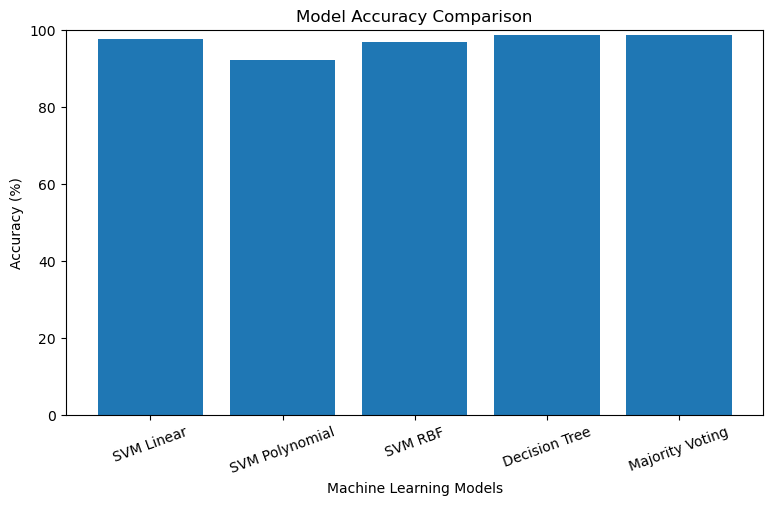

In [114]:
labels = model_columns + ["Majority Voting"]

plt.figure(figsize=(9, 5))

plt.bar(labels, scores)

plt.title("Model Accuracy Comparison")
plt.xlabel("Machine Learning Models")
plt.ylabel("Accuracy (%)")

plt.ylim(0, 100)
plt.xticks(rotation=20)

plt.show()

In [115]:
# Majority Voting Evaluation


In [116]:
print("Total Test Samples:", len(predictions))

print("Majority Cases:", len(majority_cases))

print("Correct Majority Predictions:", len(correct_majority))

print("Incorrect Majority Predictions:",
      len(majority_cases) - len(correct_majority))

print("Majority Voting Accuracy:",
      round(len(correct_majority) / len(majority_cases) * 100, 2), "%")

print("Majority Voting Coverage:",
      round(len(majority_cases) / len(predictions) * 100, 2), "%")

Total Test Samples: 440
Majority Cases: 431
Correct Majority Predictions: 425
Incorrect Majority Predictions: 6
Majority Voting Accuracy: 98.61 %
Majority Voting Coverage: 97.95 %


In [117]:
# Disagreement Cases Analysis
disagreement_cases = predictions[
    predictions["Agreement"] == False
].copy()

for model in model_columns:
    correct = (
        disagreement_cases[model] ==
        disagreement_cases["Actual"]
    ).sum()

    print(model, "Correct Predictions:", correct)

print("Total Disagreement Cases:",
      len(disagreement_cases))


SVM Linear Correct Predictions: 31
SVM Polynomial Correct Predictions: 6
SVM RBF Correct Predictions: 27
Decision Tree Correct Predictions: 35
Total Disagreement Cases: 39


In [128]:
agree_df    = predictions[predictions["Agreement"] == True]
disagree_df = predictions[predictions["Agreement"] == False]

rows = []
for m in model_columns:
    total = (predictions[m] != predictions["Actual"]).sum()
    dis   = (disagree_df[m] != disagree_df["Actual"]).sum()
    agr   = (agree_df[m]    != agree_df["Actual"]).sum()
    rows.append({
        "Model": m,
        "Total Errors": total,
        "Disagreement Errors": dis,
        "Agreement Errors": agr,
        "Agreement Error (%)":    round(agr / len(agree_df)    * 100, 2),
        "Disagreement Error (%)": round(dis / len(disagree_df) * 100, 2)
    })

pd.DataFrame(rows)

,Model,Total Errors,Disagreement Errors,Agreement Errors,Agreement Error (%),Disagreement Error (%)
0,SVM Linear,10,8,2,0.5,20.51
1,SVM Polynomial,35,33,2,0.5,84.62
2,SVM RBF,14,12,2,0.5,30.77
3,Decision Tree,6,4,2,0.5,10.26


In [118]:
print(
    "At least One Model Correct:",
    (disagreement_cases["Correct_Count"] > 0).sum()
)

print(
    "All Models Wrong:",
    (disagreement_cases["Correct_Count"] == 0).sum()
)

At least One Model Correct: 39
All Models Wrong: 0


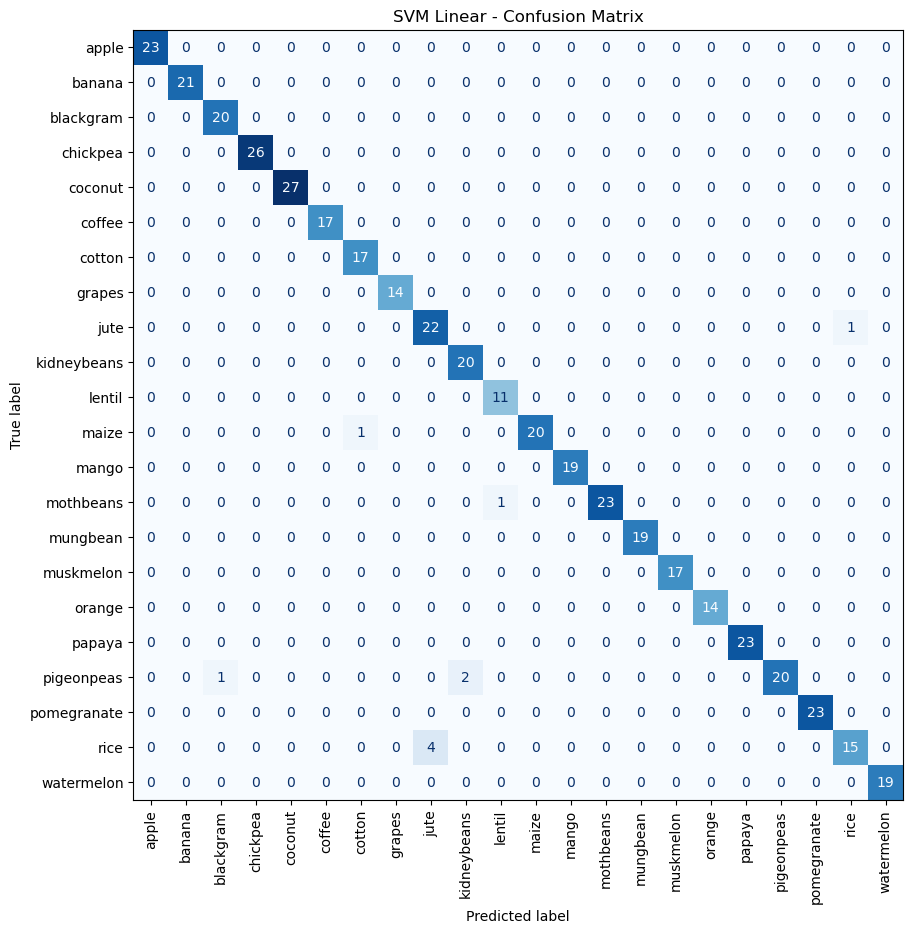

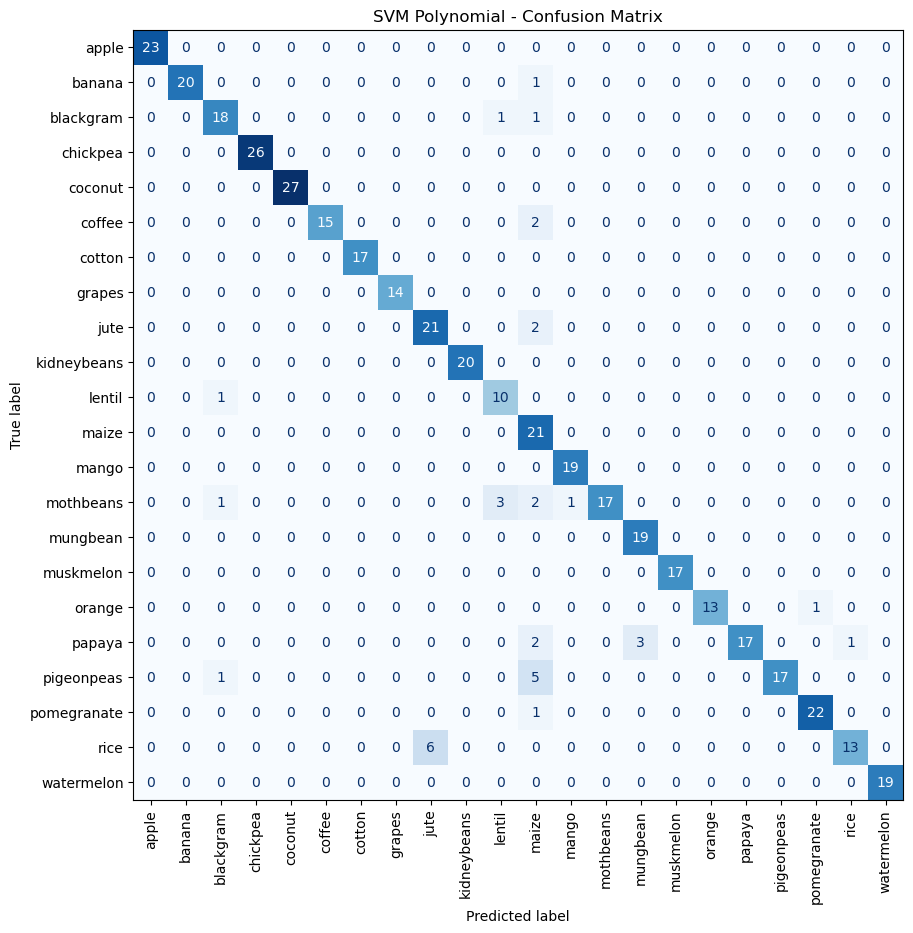

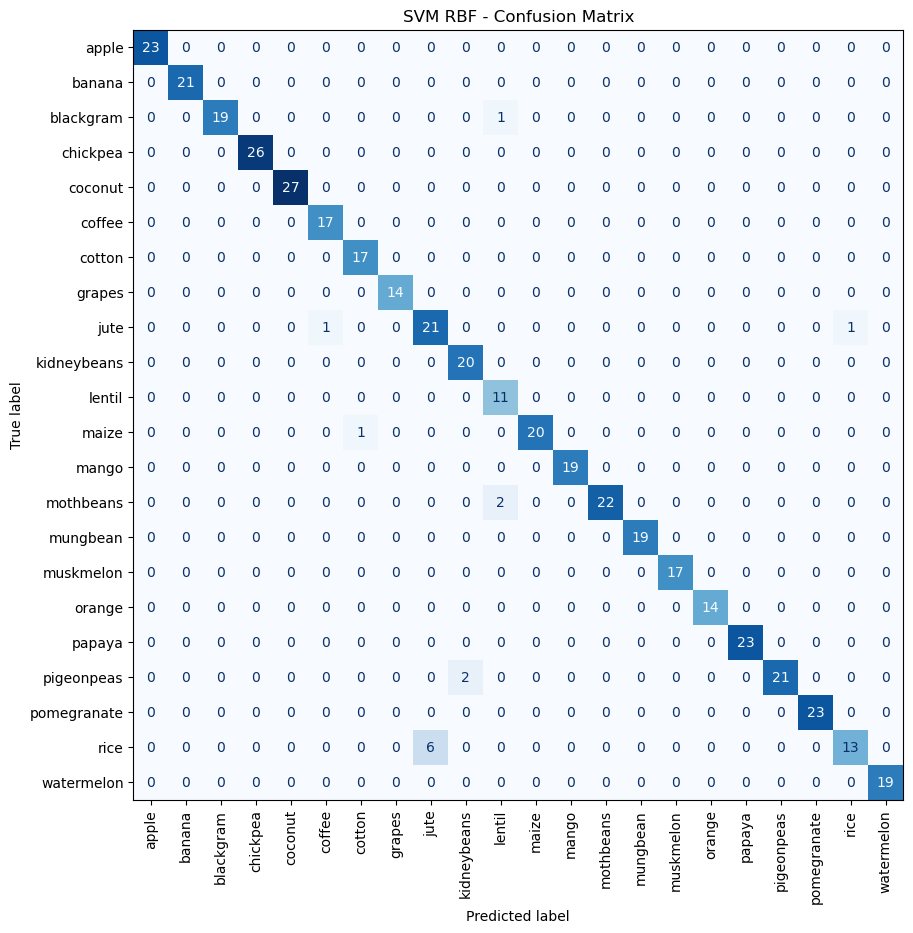

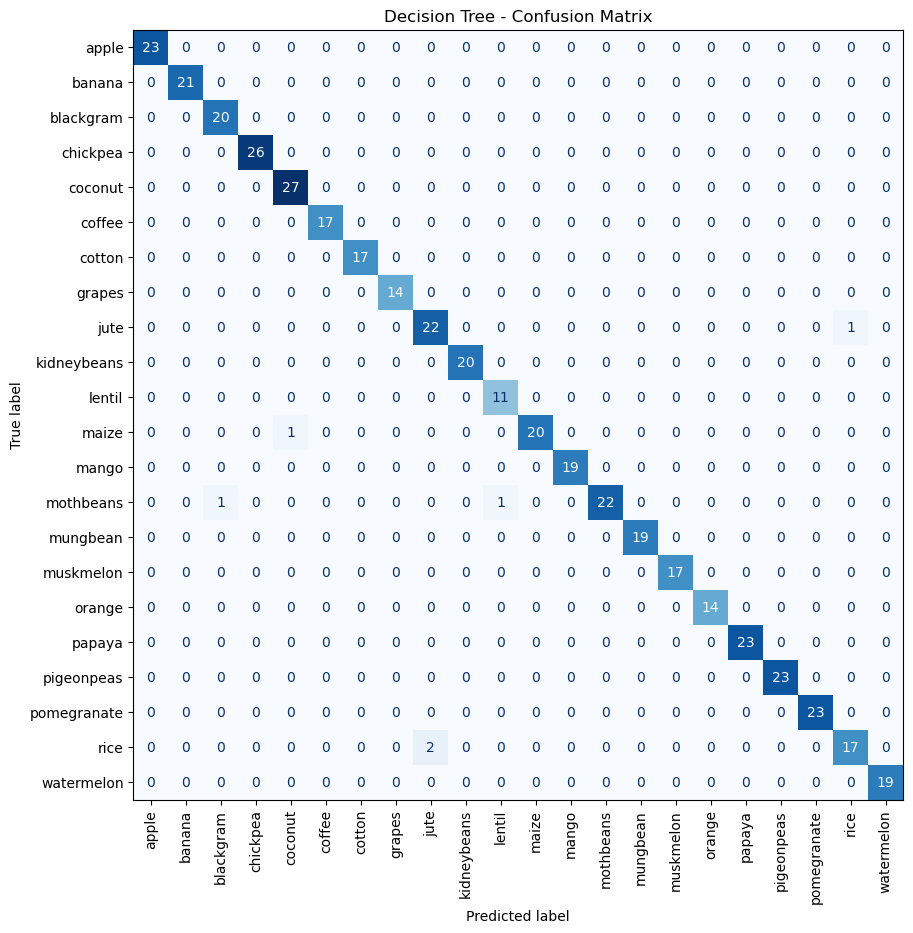

In [119]:
# Confusion Matrix
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

for name, model in models.items():

    cm = confusion_matrix(y_test, predictions[name])

    cm_display = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=model.classes_ if hasattr(model, "classes_") else sorted(y_test.unique())
    )

    fig, ax = plt.subplots(figsize=(12, 10))

    cm_display.plot(
        cmap="Blues",
        xticks_rotation=90,
        ax=ax,
        colorbar=False
    )

    plt.title(name + " - Confusion Matrix")
    plt.show()

In [120]:
from sklearn.metrics import classification_report

for name, model in models.items():

    print("\n", name)
    print("-" * 50)

    print(
        classification_report(
            y_test,
            predictions[name],
            zero_division=0
        )
    )


 SVM Linear
--------------------------------------------------
              precision    recall  f1-score   support

       apple       1.00      1.00      1.00        23
      banana       1.00      1.00      1.00        21
   blackgram       0.95      1.00      0.98        20
    chickpea       1.00      1.00      1.00        26
     coconut       1.00      1.00      1.00        27
      coffee       1.00      1.00      1.00        17
      cotton       0.94      1.00      0.97        17
      grapes       1.00      1.00      1.00        14
        jute       0.85      0.96      0.90        23
 kidneybeans       0.91      1.00      0.95        20
      lentil       0.92      1.00      0.96        11
       maize       1.00      0.95      0.98        21
       mango       1.00      1.00      1.00        19
   mothbeans       1.00      0.96      0.98        24
    mungbean       1.00      1.00      1.00        19
   muskmelon       1.00      1.00      1.00        17
      orange     

In [121]:
# Error Data
from scipy.stats import ttest_ind

agreement_errors = predictions[
    predictions["Agreement"] == True
]["Model_Errors"]

disagreement_errors = predictions[
    predictions["Agreement"] == False
]["Model_Errors"]

print("Agreement Samples:", len(agreement_errors))
print("Disagreement Samples:", len(disagreement_errors))

print("Agreement Average Errors:", agreement_errors.mean())
print("Disagreement Average Errors:", disagreement_errors.mean())

Agreement Samples: 401
Disagreement Samples: 39
Agreement Average Errors: 0.0199501246882793
Disagreement Average Errors: 1.4615384615384615


In [122]:
t_stat, p_value = ttest_ind(
    agreement_errors,
    disagreement_errors,
    equal_var=False
)

print("T-statistic:", t_stat)
print("P-value:", p_value)

if p_value < 0.05:
    print("Result: Statistically Significant")
else:
    print("Result: Not Statistically Significant")

T-statistic: -12.413580185188104
P-value: 3.781169643750345e-15
Result: Statistically Significant


In [129]:
# Agreement Strength Summary
# NOTE: this is an ORACLE measure (any model correct), NOT accuracy.
summary = []

for count in [4, 3, 2]:

    group = predictions[
        predictions["Agreement_Count"] == count
    ]

    correct = (
        group[model_columns]
        .eq(group["Actual"], axis=0)
        .any(axis=1)
    ).sum()

    accuracy = (correct / len(group)) * 100

    summary.append({
        "Agreement Count": f"{count} models agree",
        "Samples": len(group),
        "At Least One Model Correct": correct,
        "Accuracy (%)": round(accuracy, 2)
    })


# Convert into DataFrame
summary_df = pd.DataFrame(summary)


# Display Table
from IPython.display import display as show_table

show_table(summary_df)

,Agreement Count,Samples,At Least One Model Correct,Accuracy (%)
0,4 models agree,401,399,99.5
1,3 models agree,30,30,100.0
2,2 models agree,9,9,100.0


In [124]:
# Majority Prediction Accuracy by Agreement Strength
# reuses predictions["Majority_Prediction"] instead of recomputing votes
strength_rows = []

for count in [4, 3]:
    group = predictions[predictions["Agreement_Count"] == count]
    correct = (group["Majority_Prediction"] == group["Actual"]).sum()
    strength_rows.append({
        "Agreement Strength": f"{count} models agree",
        "Total Samples": len(group),
        "Correct Majority Predictions": correct,
        "Incorrect Majority Predictions": len(group) - correct,
        "Majority Accuracy (%)": round(correct / len(group) * 100, 2)
    })

majority_results = pd.DataFrame(strength_rows)
display(majority_results)

,Agreement Strength,Total Samples,Correct Majority Predictions,Incorrect Majority Predictions,Majority Accuracy (%)
0,4 models agree,401,399,2,99.50
1,3 models agree,30,26,4,86.67


In [125]:
# Coverage-Risk Analysis all numbers computed, nothing hardcoded
total_samples = len(predictions)
rows = []
for label, min_agree in [("4 Models Agree", 4), ("At Least 3 Models Agree", 3)]:
    accepted = predictions[predictions["Agreement_Count"] >= min_agree]
    wrong = (accepted["Majority_Prediction"] != accepted["Actual"]).sum()
    rows.append({
        "Agreement Threshold": label,
        "Accepted Samples": len(accepted),
        "Coverage (%)": round(len(accepted) / total_samples * 100, 2),
        "Incorrect Predictions": int(wrong),
        "Risk (%)": round(wrong / len(accepted) * 100, 2)
    })
coverage_results = pd.DataFrame(rows)
display(coverage_results)

,Agreement Threshold,Accepted Samples,Coverage (%),Incorrect Predictions,Risk (%)
0,4 Models Agree,401,91.14,2,0.50
1,At Least 3 Models Agree,431,97.95,6,1.39


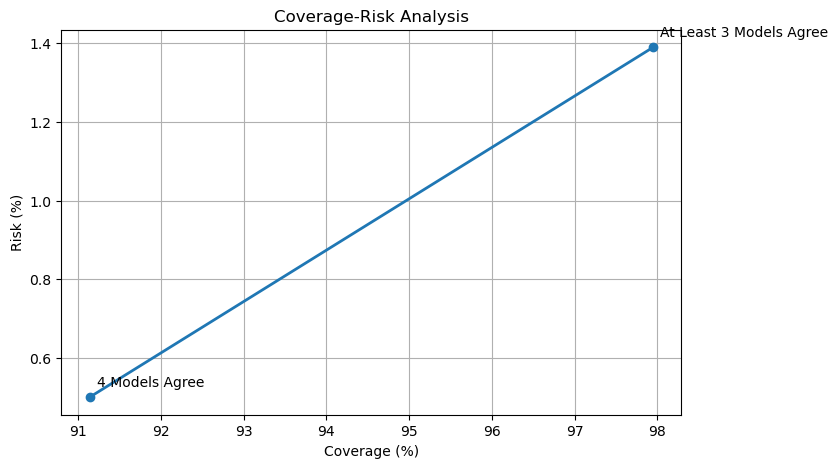

In [126]:
# Coverage-Risk Graph values taken from coverage_results
thresholds = coverage_results["Agreement Threshold"].tolist()
coverage = coverage_results["Coverage (%)"].tolist()
risk = coverage_results["Risk (%)"].tolist()

plt.figure(figsize=(8, 5))
plt.plot(coverage, risk, marker="o", linewidth=2)
for k in range(len(thresholds)):
    plt.annotate(thresholds[k], (coverage[k], risk[k]),
                 xytext=(5, 8), textcoords="offset points")
plt.title("Coverage-Risk Analysis")
plt.xlabel("Coverage (%)")
plt.ylabel("Risk (%)")
plt.grid(True)
plt.show()